# Function 3 - Week 6: Exploration review

Review of measured outputs and input coverage through the **Week 5 return, received on 30 October 2026 at 14:57 GMT**.

The independent official snapshot contains **15 initial observations and five returned queries (20 rows)**. All 3 input settings lie in `[0, 1)`. Larger signed outputs are better. Earlier snapshots and separate cohort analyses retain their historical evidence.

The latest output is **-0.0983688537525**, **rank 12/20 (1 = highest output)**. It does not improve the prior incumbent of **-0.0348353133501**. Original inputs and outputs remain at full precision in the local CSV and structured result record.


In [1]:
# Imports and shared helpers.
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display

shared_dir = next(
    (folder / "Shared" for folder in (Path.cwd(), *Path.cwd().parents)
     if (folder / "Shared" / "exploration_review_helpers.py").is_file()), None,
)
if shared_dir is None:
    raise FileNotFoundError("Run from this notebook's folder inside notebooks/.")
if str(shared_dir) not in sys.path:
    sys.path.insert(0, str(shared_dir))

from exploration_review_helpers import load_exploration_review, remaining_exploration_queries
from plot_helpers import (
    PLOT_CONFIG, plot_output_number_line, plot_sampling_gap_projections,
    plot_fixed_exploration_projections,
)
from three_input_model_helpers import plot_observed_input_cloud
print("Python:", sys.executable)


Python: C:\_Source\Imperial-ML-AI-Live\Capstone\imperial-capstone\.venv\Scripts\python.exe


In [2]:
# Settings for this run. Preserve the saved planning coordinates at full precision.
FUNCTION_NUMBER = 3
CURRENT_WEEK = 6
INPUT_COLUMNS = ["x1", "x2", "x3"]
OUTPUT_COLUMN = "y"
EXPECTED_ROUND_COUNTS = {0: 15, 1: 1, 2: 1, 3: 1, 4: 1, 5: 1}
ANALYSIS_DIR = Path.cwd().resolve()
DATA_PATH = ANALYSIS_DIR / "observations.csv"
FIGURES_DIR = ANALYSIS_DIR / "figures"
TITLE = f"Function {FUNCTION_NUMBER} - Week {CURRENT_WEEK}"
FIRST_PLAN_WEEK = 2
PORTAL_DECIMALS = 6
PLANNED_QUERIES = pd.DataFrame([
    [0.9545240919577334, 0.8194703192896731, 0.04216282607444466],
    [0.3523200058361702, 0.9307991516470914, 0.8498485887799658],
    [0.9038419399841349, 0.2689031599827457, 0.8751995976599097],
], columns=INPUT_COLUMNS)
OUTPUT_ZOOM_LIMITS = (-0.15, 0.0)
INPUT_PAIRS = [("x1", "x2"), ("x1", "x3"), ("x2", "x3")]
STORYBOARD_SIZE = (14, 9.4)
CLOUD_SETTINGS = dict(colourscale="Plasma", width=850, height=560)
WEEK_DIR = ANALYSIS_DIR.parent


In [3]:
# Validate the snapshot before plotting it.
review = load_exploration_review(
    DATA_PATH, input_columns=INPUT_COLUMNS, output_column=OUTPUT_COLUMN,
    expected_round_counts=EXPECTED_ROUND_COUNTS,
)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
display(review["latest_submissions"].drop(columns="comparison"))
print(review["report"])


,observation_id,source_round,x1,x2,x3,y,output_rank
19,round-05,5,0.65846,0.558234,0.006012,-0.098369,12


Latest recorded submission: round 5 (1 new output).
Compared with 19 earlier observations (20 outputs in total).
Earlier output range: [-0.398925513146, -0.0348353133501].

round-05: y = -0.0983688537525 (negative); rank 12/20 (1 = highest output).
Inputs: x1 = 0.65846, x2 = 0.558234, x3 = 0.006012
Within the earlier output range.


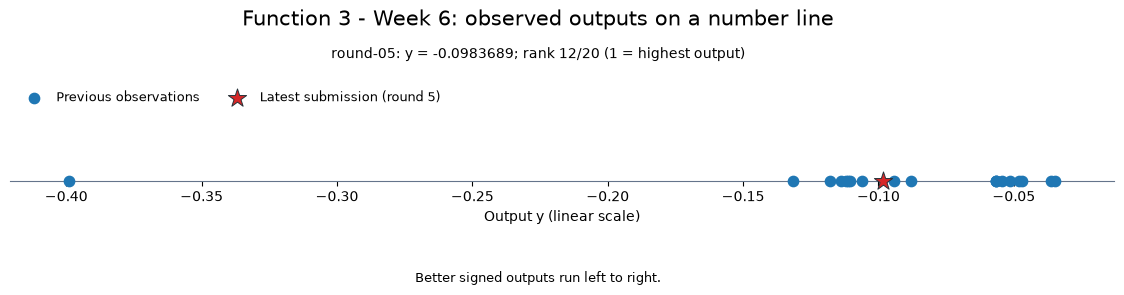

In [4]:
# Original output units and ranks, followed by a display-only zoom.
plot_output_number_line(
    review, title=f"{TITLE}: observed outputs on a number line",
    save_to=FIGURES_DIR / "output-number-line.png",
)

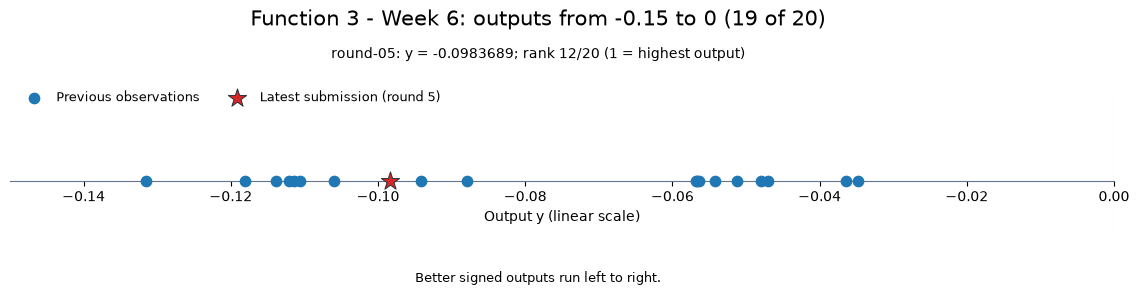

In [5]:
outputs_in_zoom = int(review["outputs"].between(*OUTPUT_ZOOM_LIMITS).sum())
plot_output_number_line(
    review, output_limits=OUTPUT_ZOOM_LIMITS,
    title=f"{TITLE}: outputs from {OUTPUT_ZOOM_LIMITS[0]:g} to {OUTPUT_ZOOM_LIMITS[1]:g} ({outputs_in_zoom} of {len(review['data'])})",
    save_to=FIGURES_DIR / "output-number-line-zoom.png",
)

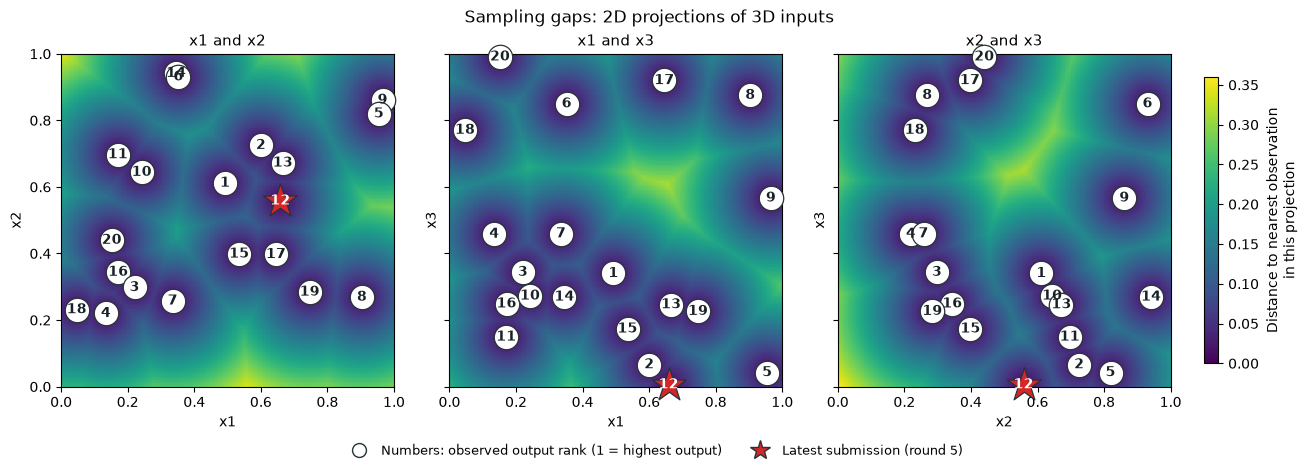

In [6]:
# These distances are measured within each displayed input-pair projection.
plot_sampling_gap_projections(
    review["plot_data"], input_columns=INPUT_COLUMNS, pairs=INPUT_PAIRS,
    highlight=review["latest_mask"], highlight_label=f"Latest submission (round {review['latest_round']})",
    save_to=FIGURES_DIR / "sampling-gaps.png",
)

In [7]:
# All three axes are inputs; measured output is colour, with no fitted surface.
cloud = plot_observed_input_cloud(
    review["inputs"].to_numpy(), review["outputs"].to_numpy(),
    title=f"Function {FUNCTION_NUMBER}: observed outputs in the three-input space", **CLOUD_SETTINGS,
    save_to=FIGURES_DIR / "observed-input-cloud.html",
)
cloud.show(config={**PLOT_CONFIG, "responsive": CLOUD_SETTINGS["width"] is None})

In [8]:
# Filter this display only; calculations and observed ranks retain every observation.
cloud_zoom = plot_observed_input_cloud(
    review["inputs"].to_numpy(), review["outputs"].to_numpy(), output_limits=OUTPUT_ZOOM_LIMITS,
    title=f"Function {FUNCTION_NUMBER}: outputs from {OUTPUT_ZOOM_LIMITS[0]:g} to {OUTPUT_ZOOM_LIMITS[1]:g} ({outputs_in_zoom} of {len(review['data'])})",
    best_label="Best output in this view", **CLOUD_SETTINGS,
    save_to=FIGURES_DIR / "observed-input-cloud-zoom.html",
)
cloud_zoom.show(config={**PLOT_CONFIG, "responsive": CLOUD_SETTINGS["width"] is None})

The following storyboard records the completed Week 2–4 fixed plan only. The new round 5 model-led point appears in the current coverage view above.

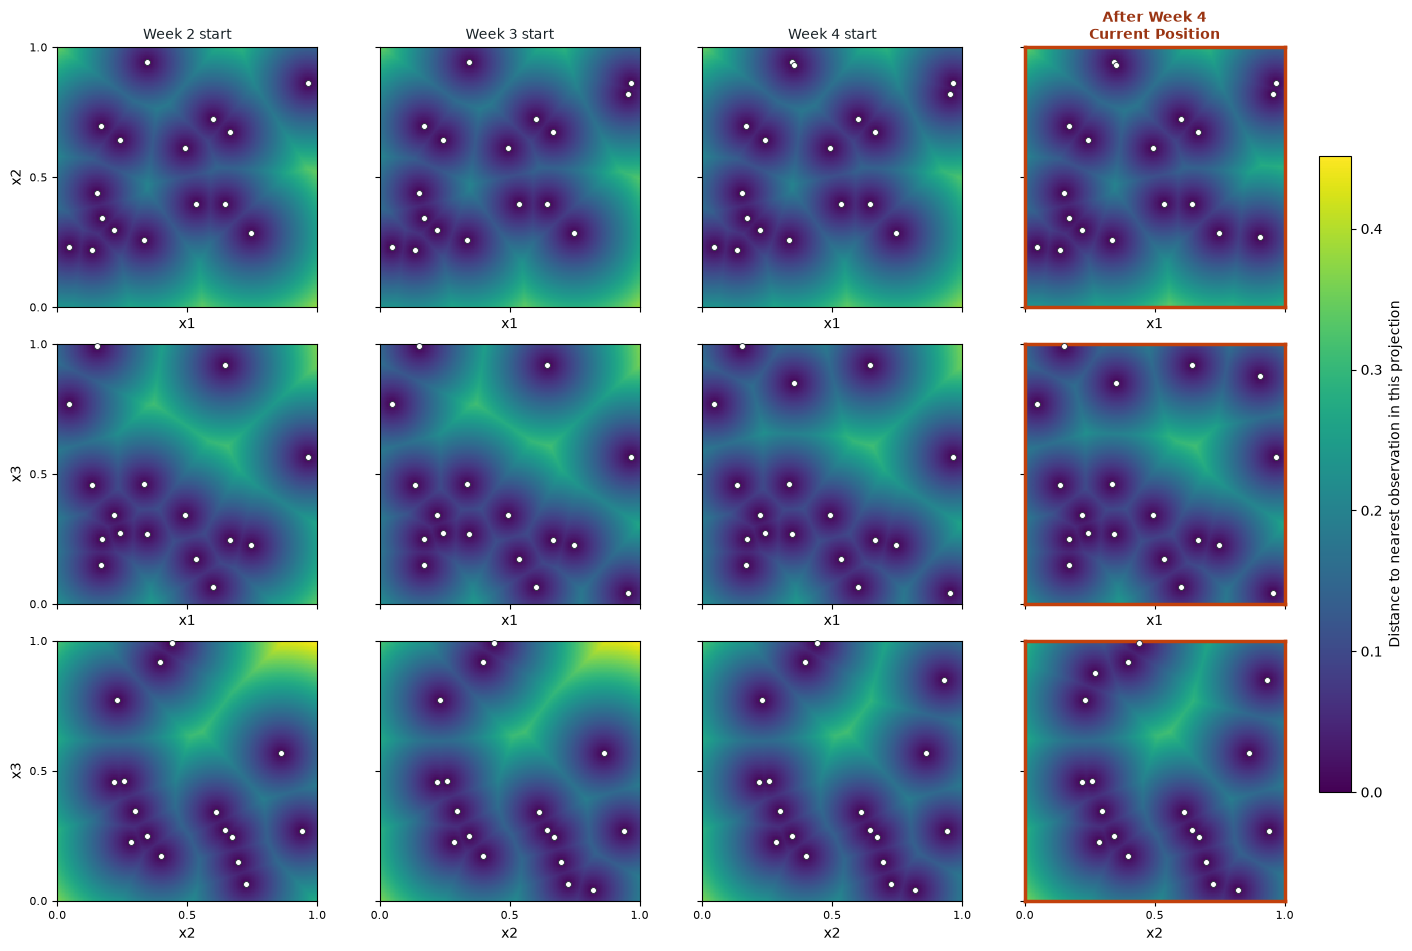

In [9]:
# Recorded official inputs establish the timeline, including their portal precision.
plot_fixed_exploration_projections(
    review["data"].loc[review["data"].source_round < 5], PLANNED_QUERIES, current_week=5,
    first_plan_week=FIRST_PLAN_WEEK, pairs=INPUT_PAIRS, figsize=STORYBOARD_SIZE,
    save_to=FIGURES_DIR / "fixed-exploration-progression-projections.png",
)

In [10]:
# An empty table means the predetermined shortlist has no remaining query.
remaining_plan = remaining_exploration_queries(
    PLANNED_QUERIES, current_week=CURRENT_WEEK, first_plan_week=FIRST_PLAN_WEEK, precision=PORTAL_DECIMALS,
)
display(remaining_plan.style.format({column: f"{{:.{PORTAL_DECIMALS}f}}" for column in INPUT_COLUMNS}))

,x1,x2,x3,Portal input
Week,,,,


In [11]:
from pathlib import Path
import hashlib
import json
import sys
import numpy as np
import pandas as pd
from IPython.display import display

shared_dir = next(
    (folder / "Shared" for folder in (Path.cwd(), *Path.cwd().parents)
     if (folder / "Shared" / "exploration_review_helpers.py").is_file()), None,
)
if shared_dir is None:
    raise FileNotFoundError("Run from this notebook's own week folder.")
if str(shared_dir) not in sys.path:
    sys.path.insert(0, str(shared_dir))
from exploration_review_helpers import load_exploration_review
from observation_review_helpers import (
    prepare_weekly_observation_review, plot_input_profiles,
    plot_output_review, plot_round_progress,
)
from query_budget import remaining_queries

prepared = prepare_weekly_observation_review(review)


### Progress across completed rounds

The initial rows form one starting batch. Compare each return with the best known before that round.

In [12]:
display(prepared["progress"].set_index("stage")[["returned_y", "best_y", "change_vs_prior_best"]]
    .rename(columns={"returned_y": "Returned output", "best_y": "Best observed after stage",
                     "change_vs_prior_best": "Return minus previous best"})
    .style.format(precision=6, na_rep="Not applicable"))


,Returned output,Best observed after stage,Return minus previous best
stage,,,
Initial batch,Not applicable,-0.034835,Not applicable
Round 1,-0.056431,-0.034835,-0.021596
Round 2,-0.051282,-0.034835,-0.016447
Round 3,-0.054209,-0.034835,-0.019373
Round 4,-0.056642,-0.034835,-0.021807
Round 5,-0.098369,-0.034835,-0.063534


### Saved Week 5 forecast at the submitted input

Read the preserved submission selection record without refitting. Posterior SD is model dependent; one forecast error does not establish calibration. UCB is a selection score, not a measured return.

In [13]:
# Read the saved selection record at the actual submitted input; no model is refitted.
stage_dir = shared_dir.parent.parent
selection_path = stage_dir / "submissions/Week_05/proposals.json"
if hashlib.sha256(selection_path.read_bytes()).hexdigest() != "6ca900244a2c11ab030075a37c7aae25ef8362651db03ddbc78b7b324cd5bcca":
    raise ValueError("The historical Week 5 selection record has changed.")
selection = next(row for row in json.loads(selection_path.read_text(encoding="utf-8"))["candidates"]
                 if row["function"] == FUNCTION_NUMBER)
actual_point = prepared["latest"][INPUT_COLUMNS].to_numpy(dtype=float)
if not np.array_equal(actual_point, np.asarray(selection["point"], dtype=float)):
    raise ValueError("Saved forecast coordinates do not match the returned query.")
historical_forecast = dict(selection.get("model_prediction") or {})
historical_forecast["data_scope"] = selection["data_scope"]
historical_forecast["actual_output"] = float(prepared["latest"][OUTPUT_COLUMN])
if "predicted_output" in historical_forecast:
    historical_forecast["actual_minus_prediction"] = (
        historical_forecast["actual_output"] - historical_forecast["predicted_output"])
else:
    historical_forecast["forecast_status"] = "Not applicable: fixed coverage selection"
display(pd.Series(historical_forecast))


predicted_output                               -0.033284
posterior_std                                   0.065885
ucb_weight                                          1.96
inside_sampled_hull                                False
ucb                                              0.09585
data_scope                 official_plus_retained_cohort
actual_output                                  -0.098369
actual_minus_prediction                        -0.065085
dtype: object

### What the return adds

The cohort-informed low-x3 proposal returned below the previous incumbent and below its saved model mean. It was outside the sampled convex hull and was selected largely for exploration. This result weakens confidence in that particular low-x3 candidate, without isolating an x3 effect: all three settings changed together. The course description does not specify noisy outputs for this function; no noise claim is inferred here.

In [14]:
# Full-precision review record; tiny signed outputs are never rounded to zero.
observation_summary = {
    "function": FUNCTION_NUMBER, "week": CURRENT_WEEK, "observations": len(review["data"]),
    "latest_id": prepared["latest"]["observation_id"],
    "latest_output": float(prepared["latest"][OUTPUT_COLUMN]),
    "latest_rank": int(review["latest_submissions"].iloc[0]["output_rank"]),
    "rank_definition": "1 = highest output",
    "best_id": prepared["incumbent"]["observation_id"],
    "best_observed_output": float(prepared["incumbent"][OUTPUT_COLUMN]),
    "positive_outputs": int((review["outputs"] > 0).sum()),
    "negative_outputs": int((review["outputs"] < 0).sum()),
    "exact_zeros": int((review["outputs"] == 0).sum()),
    "progress": prepared["progress"].fillna("not_applicable").to_dict(orient="records"),
    "official_history_comparison": prepared["neighbour_summary"],
    "historical_forecast": historical_forecast,
    "remaining_queries": remaining_queries(WEEK_DIR),
}
print(json.dumps(observation_summary, indent=2))


{
  "function": 3,
  "week": 6,
  "observations": 20,
  "latest_id": "round-05",
  "latest_output": -0.09836885375246775,
  "latest_rank": 12,
  "rank_definition": "1 = highest output",
  "best_id": "initial-004",
  "best_observed_output": -0.034835313350078584,
  "positive_outputs": 0,
  "negative_outputs": 20,
  "exact_zeros": 0,
  "progress": [
    {
      "source_round": 0,
      "stage": "Initial batch",
      "returned_y": "not_applicable",
      "best_y": -0.034835313350078584,
      "change_vs_prior_best": "not_applicable"
    },
    {
      "source_round": 1,
      "stage": "Round 1",
      "returned_y": -0.0564311593911001,
      "best_y": -0.034835313350078584,
      "change_vs_prior_best": -0.021595846041021514
    },
    {
      "source_round": 2,
      "stage": "Round 2",
      "returned_y": -0.051282396335886896,
      "best_y": -0.034835313350078584,
      "change_vs_prior_best": -0.016447082985808312
    },
    {
      "source_round": 3,
      "stage": "Round 3",
     

### Course lifecycle for this review

1. **Define the goal and scope** — review round 5 for the project owner and prepare evidence for the Week 6 decision; success means a reconciled return and an accurate descriptive review.
2. **Gather the data** — use the retained 30 October results email, original cumulative attachments and independent official CSV snapshot.
3. **Explore the data** — inspect measured ranks, progress and coverage or full input profiles.
4. **Clean and preprocess the data** — validate dimensions, bounds, finite values and round counts; preserve all rows and full float64 precision.
5. **Select and engineer features** — retain the existing ordered input coordinates; no engineered features are required.
6. **Define the machine-learning task** — continuous black-box maximisation remains the task; this notebook provides descriptive evidence.
7. **Partition the data** — not applicable: no new model is fitted or validated in this observation review.
8. **Select and train candidate methods** — not applicable: any Week 6 model comparison is separate work.
9. **Evaluate and interpret the results** — compare the measured return with earlier outputs, the prior incumbent and the saved forecast where one informed selection.
10. **Deploy and iterate** — no deployment applies; carry this evidence into the next query review. Eight query opportunities remain, including Week 6; this notebook submits no query.
